In [44]:
import subprocess
try:
  import google.colab
  subprocess.run(['python','-m','pip','install','skorch','torch'])
except ImportError:
  pass


In [45]:
from sklearn.datasets import fetch_openml #dataset
from sklearn.model_selection import train_test_split #helps to split dataset
import numpy as np #number handling library in python
import matplotlib.pyplot as plt #ploting library to see image



In [46]:
mnist = fetch_openml('mnist_784', as_frame=False, cache=True)


/usr/local/lib/python3.10/dist-packages/sklearn/datasets/_openml.py:1022: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [47]:
mnist.data.shape

(70000, 784)

In [48]:
x = mnist.data.astype('float32')#x is features which is 784, less throughput more accuracy
y = mnist.target.astype('int64')#y is label more throughout less accuracy


In [49]:
x /= 255.0 #normalization min:max 0 to 255 will become 0.0 to 1.0

In [50]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42) #data classification

In [51]:
len(x_train)


56000

In [52]:
assert(x_train.shape[0] == y_train.shape[0])
assert(x_test.shape[0] == y_test.shape[0])
assert(x_train.shape[0] + x_test.shape[0] == mnist.data.shape[0])

In [53]:
def plot_example(x,y):
  for i, (img,y) in enumerate(zip(x[:5].reshape(5,28,28), y[:5])):
    plt.subplot(151+i)
    plt.imshow(img)
    plt.xticks([])
    plt.yticks([])

    plt.title(y)
    # plt.axis('off')
    # plt.subplot(2,5,i+1

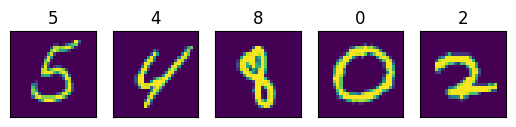

In [54]:
plot_example(x_train,y_train)

In [55]:
import torch
from torch import nn
import torch.nn.functional as F

In [56]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'


In [57]:
mnist_dim = x.shape[1]
hidden_dim = int(mnist_dim/8)
output_dim = len(np.unique(mnist.target))

In [58]:
mnist_dim, hidden_dim, output_dim


(784, 98, 10)

In [59]:
class ClassifierModule(nn.Module):
  def __init__(self, input_dim=mnist_dim, hidden_dim=hidden_dim, output_dim=output_dim, dropout=0.5):
    super(ClassifierModule, self).__init__()
    self.dropout = nn.Dropout(dropout)
    self.hidden = nn.Linear(input_dim, hidden_dim)
    self.output = nn.Linear(hidden_dim, output_dim)

  def forward(self, x, **kwargs):
    x = F.relu(self.hidden(x))
    x = self.dropout(x)
    x = F.softmax(self.output(x), dim=-1)
    return x


In [60]:
from skorch import NeuralNetClassifier

In [65]:
torch.manual_seed(0)
net = NeuralNetClassifier(
    ClassifierModule,
    max_epochs=200,
    lr=0.1,
    device=device
)

In [66]:
net.fit(x_train, y_train);

  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.8181       0.8974        0.3837  1.6600
      2        0.4286       0.9144        0.3005  0.9921
      3        0.3550       0.9257        0.2581  0.9561
      4        0.3165       0.9327        0.2295  0.9736
      5        0.2925       0.9396        0.2101  0.9847
      6        0.2703       0.9433        0.1947  0.9524
      7        0.2573       0.9461        0.1825  0.9930
      8        0.2381       0.9495        0.1719  0.9606
      9        0.2324       0.9516        0.1639  0.9626
     10        0.2192       0.9532        0.1574  0.9630
     11        0.2148       0.9543        0.1517  0.9610
     12        0.2065       0.9560        0.1466  1.1926
     13        0.1999       0.9580        0.1422  1.3260
     14        0.1935       0.9582        0.1387  1.0507
     15        0.1901       0.9596        0.1352  0.9573
     16        0.1843       0.9

In [67]:
from sklearn.metrics import accuracy_score
y_pred = net.predict(x_test)
accuracy_score(y_test, y_pred)

0.9717142857142858

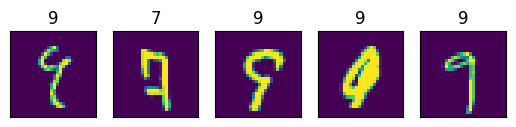

In [68]:
error_mark = y_pred != y_test
plot_example(x_test[error_mark], y_test[error_mark])